# Notebook 04
* Author: Melissa Ormeño
* Date: May 2024

Aims:
* Obiene las mutaciones por tipo de cancer ya clasificadas por su frecuencia de alelo mutante
* Grafica el numero de mutaciones por gen y por tipo de cancer

In [2]:
# Dependences
import pandas as pd
import altair as alt

# Step1: Obtener data frame que contenga los aminoacidos mutados

In [3]:
# DF obtenido del notebook 03
# Contiene la data clasificada por frecuencia de alelo mutante
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
df_cancer = pd.read_csv('../data/mutaciones/df_count_mut_{0}.csv'.format(family_name))
print(df_cancer.shape)
print(df_cancer.columns)
df_cancer.head(2)

(3321, 7)
Index(['Gen_names', 'icgc_donor_id', 'aa_mutation', 'consequence_type',
       'tipo_cancer', 'total_read_count', 'mutant_allele_read_count'],
      dtype='object')


,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0


In [4]:
df_cancer['Gen_names'].unique()

array(['ACVR1', 'ACVR1B', 'ACVR1C', 'ACVR2A', 'ACVR2B', 'ACVRL1', 'AMHR2',
       'BMPR1A', 'BMPR1B', 'BMPR2', 'TGFBR1', 'TGFBR2'], dtype=object)

In [5]:
# Diccionario con los acrónimos que quieres agregar
acronimos = {'ACVR1' : 'ALK2' , 
             'ACVR1B' : 'ALK4', 
             'ACVR1C' : 'ALK7', 
             'ACVR2A' : 'ACVR2A', 
             'ACVR2B' : 'ACVR2B', 
             'ACVRL1' : 'ALK1' , 
             'AMHR2' : 'AMHR2',
            'BMPR1A' : 'ALK3', 
             'BMPR1B' : 'ALK6', 
             'BMPR2' : 'BMPR2', 
             'TGFBR1' : 'ALK5', 
             'TGFBR2' : 'TGFBR2'
 
}



# Crear la columna de acrónimos utilizando el mapeo
df_cancer['Alias'] = df_cancer['Gen_names'].map(acronimos)
df_cancer

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2
2,ACVR1,DO10880,V214A,missense_variant,Cerebro,101.0,52.0,ALK2
3,ACVR1,DO13522,L337S,missense_variant,Cerebro,67.0,50.0,ALK2
4,ACVR1,DO14208,W412L,missense_variant,Cabeza,34.0,3.0,ALK2
...,...,...,...,...,...,...,...,...
3316,TGFBR2,DO8490,R403H,missense_variant,Colon,180.0,7.0,TGFBR2
3317,TGFBR2,DO8490,R428H,missense_variant,Colon,180.0,7.0,TGFBR2
3318,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2
3319,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2


In [6]:
# Diccionario con tipo de receptor que quieres agregar
acronimos = {'ACVR1' : 'Tipo I' , 
             'ACVR1B' : 'Tipo I', 
             'ACVR1C' : 'Tipo I', 
             'ACVR2A' : 'Tipo II', 
             'ACVR2B' : 'Tipo II', 
             'ACVRL1' : 'Tipo I' , 
             'AMHR2' : 'Tipo II',
            'BMPR1A' : 'Tipo I', 
             'BMPR1B' : 'Tipo I', 
             'BMPR2' : 'Tipo II', 
             'TGFBR1' : 'Tipo I', 
             'TGFBR2' : 'Tipo II'
 
}



# Crear la columna de acrónimos utilizando el mapeo
df_cancer['tipo_receptor'] = df_cancer['Gen_names'].map(acronimos)
df_cancer

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2,Tipo I
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2,Tipo I
2,ACVR1,DO10880,V214A,missense_variant,Cerebro,101.0,52.0,ALK2,Tipo I
3,ACVR1,DO13522,L337S,missense_variant,Cerebro,67.0,50.0,ALK2,Tipo I
4,ACVR1,DO14208,W412L,missense_variant,Cabeza,34.0,3.0,ALK2,Tipo I
...,...,...,...,...,...,...,...,...,...
3316,TGFBR2,DO8490,R403H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II
3317,TGFBR2,DO8490,R428H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II
3318,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II
3319,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II


In [7]:
# Diccionario con los rangos de dominios por gen
gene_domain_ranges = {
    'ACVR1':  {'GS': (178, 208), 'Kinasa': (209, 502)},
    'ACVR1B': {'GS': (177, 207), 'Kinasa': (208, 497)},
    'ACVR1C': {'GS': (165, 195), 'Kinasa': (196, 485)},
    'ACVR2A': {'Kinasa': (192, 485)},
    'ACVR2B': {'Kinasa': (194, 484)},
    'ACVRL1': {'GS': (172, 202), 'Kinasa': (203, 493)},
    'AMHR2':  {'Kinasa': (203, 518)},
    'BMPR1A': {'GS': (204, 234), 'Kinasa': (235, 525)},
    'BMPR1B': {'GS': (174, 204), 'Kinasa': (205, 502)},
    'BMPR2':  {'Kinasa': (203, 504)},
    'TGFBR1': {'GS': (175, 205), 'Kinasa': (206, 495)},
    'TGFBR2': {'Kinasa': (244, 544)},
    
}

# Función para determinar el dominio según el gen y la posición
def assign_domain(row):
    gene = row['Gen_names']
    mutation = row['aa_mutation']
    if gene in gene_domain_ranges:
        position = int(''.join(filter(str.isdigit, mutation)))  # Extraer el número de la mutación
        for domain, (start, end) in gene_domain_ranges[gene].items():
            if start <= position <= end:
                return domain
    return 'Otro'  # Asignar 'Otro' si no está en ningún rango

# Aplicar la función al DataFrame
df_cancer['Dominio'] = df_cancer.apply(assign_domain, axis=1)

# Verificar el resultado
df_cancer

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2,Tipo I,Otro
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2,Tipo I,Kinasa
2,ACVR1,DO10880,V214A,missense_variant,Cerebro,101.0,52.0,ALK2,Tipo I,Kinasa
3,ACVR1,DO13522,L337S,missense_variant,Cerebro,67.0,50.0,ALK2,Tipo I,Kinasa
4,ACVR1,DO14208,W412L,missense_variant,Cabeza,34.0,3.0,ALK2,Tipo I,Kinasa
...,...,...,...,...,...,...,...,...,...,...
3316,TGFBR2,DO8490,R403H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa
3317,TGFBR2,DO8490,R428H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa
3318,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa
3319,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa


In [8]:
print(f"Numero de pacientes en tkl: {df_cancer['icgc_donor_id'].nunique()}")
print(f"Numero total de lecturas de todos los pacientes tkl (por millon): {df_cancer['total_read_count'].sum(numeric_only=True)/10**6}")
print(f"Numero total de mutaciones: {df_cancer['aa_mutation'].nunique()}")
print(f"Canceres: {df_cancer['tipo_cancer'].unique()}")
print(f"Numero de canceres: {df_cancer['tipo_cancer'].nunique()}")

Numero de pacientes en tkl: 1061
Numero total de lecturas de todos los pacientes tkl (por millon): 0.390428
Numero total de mutaciones: 2744
Canceres: ['Colon' 'Cerebro' 'Cabeza' 'Vejiga' 'Utero' 'Piel' 'Higado' 'Pulmon'
 'Ovario' 'Seno ' 'Pancreas' 'Estomago' 'Riñon' 'Vesicula' 'Sangre'
 'Prostata' 'Cervix' 'Hueso']
Numero de canceres: 18


In [9]:
df_mut = df_cancer.groupby(['Gen_names', 'aa_mutation', 'tipo_cancer'])['total_read_count'].sum().reset_index(name = 'total_read_count')
df_mut

,Gen_names,aa_mutation,tipo_cancer,total_read_count
0,ACVR1,A134T,Utero,164.0
1,ACVR1,A181P,Ovario,49.0
2,ACVR1,A233V,Piel,146.0
3,ACVR1,A317V,Utero,239.0
4,ACVR1,A471S,Colon,673.0
...,...,...,...,...
3124,TGFBR2,Y284D,Pancreas,108.0
3125,TGFBR2,Y424C,Estomago,78.0
3126,TGFBR2,Y449C,Estomago,78.0
3127,TGFBR2,YEE281,Colon,72.0


In [10]:
df_cancer[df_cancer['tipo_cancer']=='Hueso']

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio
2396,BMPR2,DO52572,RL32,frameshift_variant,Hueso,46.0,5.0,BMPR2,Tipo II,Otro


## Contar numero de mutaciones

In [11]:
#Eliminar BMPR2 en Hueso porque soplo hay un paciente y una mutacion
#df_cancer = df_cancer[~((df_cancer['Gen_names'] == 'BMPR2') & (df_cancer['tipo_cancer'] == 'Hueso'))]

In [12]:
# Paso 1: Contar el número de mutaciones únicas por gen, donante y tipo de cáncer
mutation_count = (
    df_cancer.groupby(['Gen_names', 'Alias', 'tipo_cancer','tipo_receptor','Dominio'])['aa_mutation']
    .nunique()
    .reset_index(name='mutation_count')  # Crear columna 'mutation_count' con el número de mutaciones únicas
)

# Paso 2: Sumar 'total_read_count' agrupando por gen, donante y tipo de cáncer
total_read_count = (
    df_cancer.groupby(['Gen_names', 'tipo_cancer'])['total_read_count']
    .sum()
    .reset_index(name='total_read_count')  # Crear columna 'total_read_count' con la suma
)

# Paso 3: Combinar los resultados de 'mutation_count' y 'read_count' en un solo DataFrame
read_count = pd.merge(mutation_count, total_read_count, on=['Gen_names', 'tipo_cancer'])

# Paso 4: Ordenar por el número de mutaciones
read_count = read_count.sort_values(by='mutation_count', ascending=False)

# Mostrar el resultado final
read_count

,Gen_names,Alias,tipo_cancer,tipo_receptor,Dominio,mutation_count,total_read_count
360,TGFBR1,ALK5,Utero,Tipo I,Kinasa,65,13209.0
100,ACVR1C,ALK7,Utero,Tipo I,Kinasa,64,10392.0
84,ACVR1C,ALK7,Piel,Tipo I,Kinasa,56,7526.0
60,ACVR1B,ALK4,Utero,Tipo I,Kinasa,56,7786.0
49,ACVR1B,ALK4,Pulmon,Tipo I,Kinasa,50,6037.0
...,...,...,...,...,...,...,...
96,ACVR1C,ALK7,Seno,Tipo I,GS,1,1802.0
263,BMPR1B,ALK6,Cervix,Tipo I,Otro,1,540.0
331,TGFBR1,ALK5,Cervix,Tipo I,Otro,1,726.0
162,ACVR2B,ACVR2B,Vejiga,Tipo II,Otro,1,192.0


## Normalizar por total de lecturas

## Normalizar por numero de pacientes

## Comprobar

## Grafgico de numero de mutaciones por dominio

In [13]:
read_count

,Gen_names,Alias,tipo_cancer,tipo_receptor,Dominio,mutation_count,total_read_count
360,TGFBR1,ALK5,Utero,Tipo I,Kinasa,65,13209.0
100,ACVR1C,ALK7,Utero,Tipo I,Kinasa,64,10392.0
84,ACVR1C,ALK7,Piel,Tipo I,Kinasa,56,7526.0
60,ACVR1B,ALK4,Utero,Tipo I,Kinasa,56,7786.0
49,ACVR1B,ALK4,Pulmon,Tipo I,Kinasa,50,6037.0
...,...,...,...,...,...,...,...
96,ACVR1C,ALK7,Seno,Tipo I,GS,1,1802.0
263,BMPR1B,ALK6,Cervix,Tipo I,Otro,1,540.0
331,TGFBR1,ALK5,Cervix,Tipo I,Otro,1,726.0
162,ACVR2B,ACVR2B,Vejiga,Tipo II,Otro,1,192.0


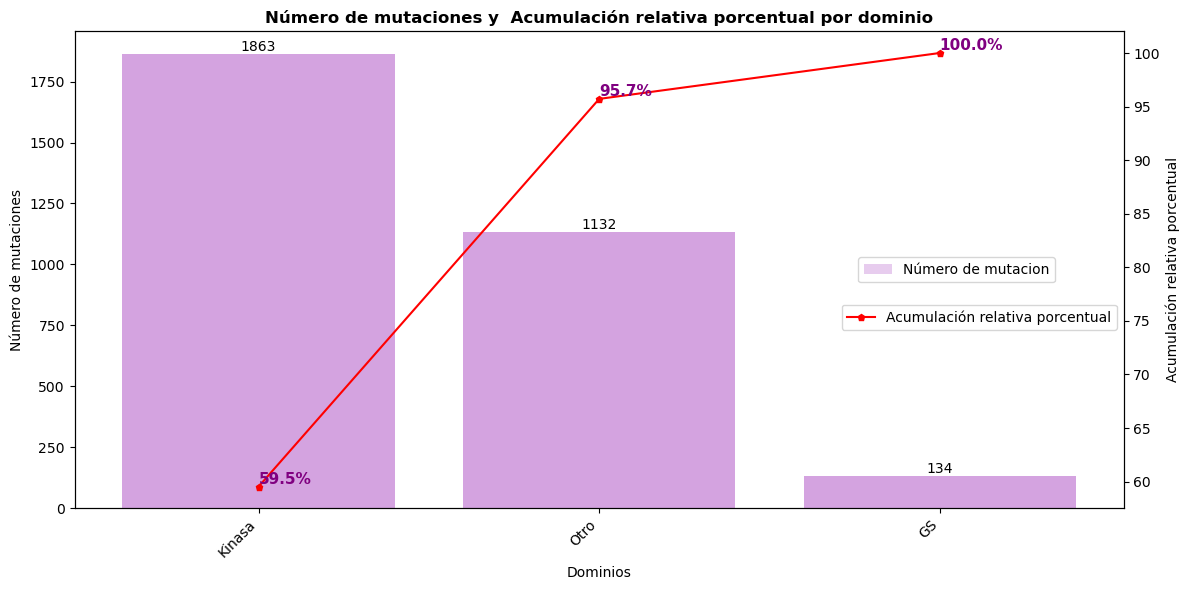

In [75]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df_variaciones ya está definido y contiene las columnas necesarias
# Agrupar por tipo de cáncer para contar las mutaciones totales
mutation_counts = read_count.groupby('Dominio', as_index=False)['mutation_count'].sum()

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='mutation_count', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutation_count'].cumsum() / mutation_counts['mutation_count'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Dominio'], mutation_counts["mutation_count"], color="#8800aa33")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Dominio'], mutation_counts['mutation_count'], color="#8800aa33", label='Número de mutacion')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color="red", marker="p", ms=5, label='Acumulación relativa porcentual')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='purple', fontsize=11,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Acumulación relativa porcentual')
ax.set_title('Número de mutaciones y  Acumulación relativa porcentual por dominio', weight='bold')
ax.set_xlabel('Dominios')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Dominio'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Dominio'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/barras_mutation_number_DOMINIO_{0}.png".format(family_name), format='png', dpi=600)

plt.show()



## Grafico de barras crudo y normalizado

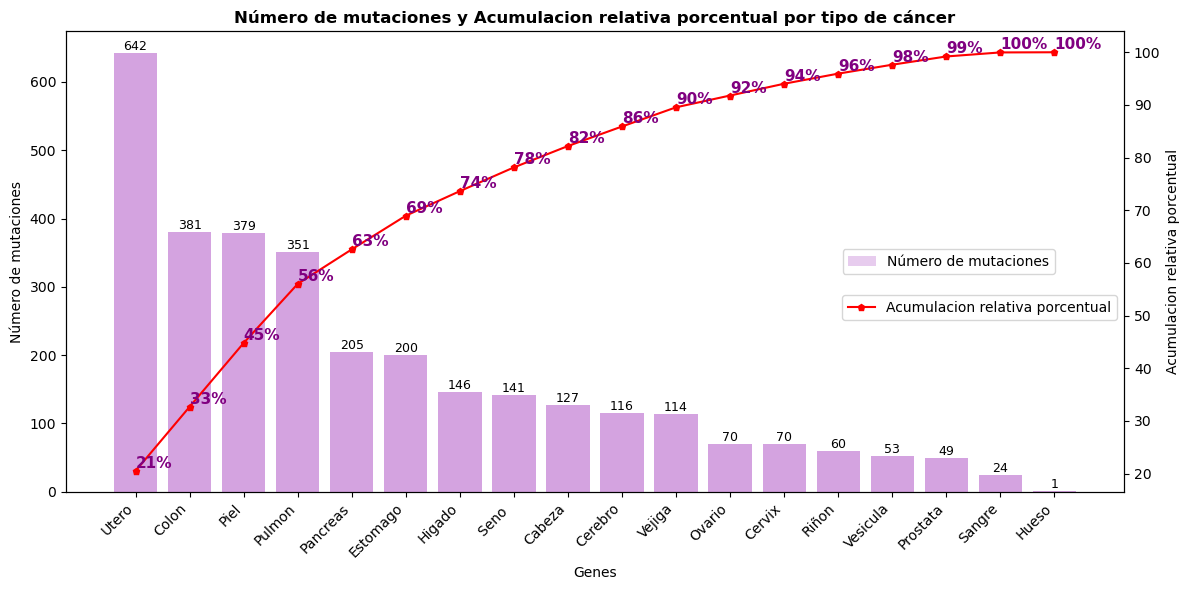

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df_variaciones ya está definido y contiene las columnas necesarias
# Agrupar por tipo de cáncer para contar las mutaciones totales
mutation_counts = read_count.groupby('tipo_cancer', as_index=False)['mutation_count'].sum()

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='mutation_count', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutation_count'].cumsum() / mutation_counts['mutation_count'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['tipo_cancer'], mutation_counts["mutation_count"], color="#8800aa33")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['tipo_cancer'], mutation_counts['mutation_count'], color="#8800aa33", label='Número de mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color="red", marker="p", ms=5, label='Acumulacion relativa porcentual')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=9)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.0f}%', ha='left', va='bottom', color='purple', fontsize=11,fontweight  = 'bold')


# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Acumulacion relativa porcentual')
ax.set_title('Número de mutaciones y Acumulacion relativa porcentual por tipo de cáncer', weight='bold')
ax.set_xlabel('Genes')
# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['tipo_cancer'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['tipo_cancer'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/barras_mutation_number_crudo_cancer_{0}.png".format(family_name), format='png', dpi=600)

plt.show()



In [20]:
read_count_genes

NameError: name 'read_count_genes' is not defined

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df_variaciones ya está definido y contiene las columnas necesarias
# Agrupar por tipo de cáncer para contar las mutaciones totales
mutation_counts = read_count_genes.groupby('Gen_names', as_index=False)['mutaciones_por_paciente'].sum()

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='mutaciones_por_paciente', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutaciones_por_paciente'].cumsum() / mutation_counts['mutaciones_por_paciente'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Gen_names'], mutation_counts["mutaciones_por_paciente"], color="#8800aa33")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Gen_names'], mutation_counts['mutaciones_por_paciente'], color="#8800aa33", label='Cantidad de Mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color="red", marker="p", ms=5, label='Relativa Acumulación Porcentual')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='purple', fontsize=11,fontweight  = 'bold')

# Ajustar límites y etiquetas
ax.set_ylabel('Cantidad de Mutaciones')
ax2.set_ylabel('Relativa Acum. Porcentual')
ax.set_title('Cantidad de Mutaciones y Acumulación Relativa Porcentual por Gen (Normalizado por paciente)')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Gen_names'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Gen_names'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
#plt.savefig("../run/imagenes/barras_mutation_number_gen_{0}.svg".format(family_name), format='svg')

plt.show()



NameError: name 'read_count_genes' is not defined

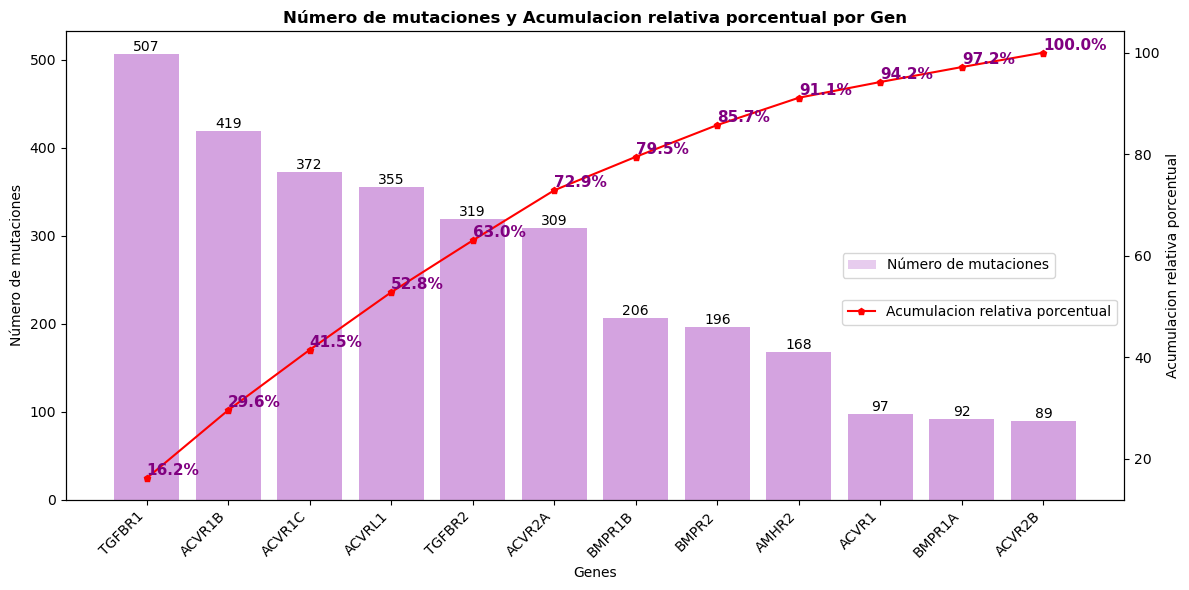

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df_variaciones ya está definido y contiene las columnas necesarias
# Agrupar por tipo de cáncer para contar las mutaciones totales
mutation_counts = read_count.groupby('Gen_names', as_index=False)['mutation_count'].sum()

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='mutation_count', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutation_count'].cumsum() / mutation_counts['mutation_count'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Gen_names'], mutation_counts["mutation_count"], color="#8800aa33")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Gen_names'], mutation_counts['mutation_count'], color="#8800aa33", label='Número de mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color="red", marker="p", ms=5, label='Acumulacion relativa porcentual')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='purple', fontsize=11,fontweight  = 'bold')

# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Acumulacion relativa porcentual')
ax.set_title('Número de mutaciones y Acumulacion relativa porcentual por Gen', weight='bold')
ax.set_xlabel('Genes')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Gen_names'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Gen_names'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/barras_mutation_number_gen_{0}.png".format(family_name), format='png', dpi=600)

plt.show()



In [24]:
print(', '.join(mutation_counts['Gen_names'].apply(lambda x: ''.join(x)).unique()))


TGFBR1, ACVR1B, ACVR1C, ACVRL1, TGFBR2, ACVR2A, BMPR1B, BMPR2, AMHR2, ACVR1, BMPR1A, ACVR2B


In [30]:
consequence = {'disruptive_inframe_insertion': 'Insercion disruptiva',
 'frameshift_variant' : 'Desplazamiento del marco',
 'inframe_deletion' : 'Delecion sin desplazamiento',
 'missense_variant' : 'Cambio de sentido',
 'start_lost': 'Perdida de codón de inicio',
 'stop_gained': 'Ganancia codón de término',
 'stop_lost': 'Perdida de códon de término',
 'stop_retained_variant': 'Terminación retenida'
              }
df_cancer['consequence_type'] = df_cancer['consequence_type'].map(consequence)

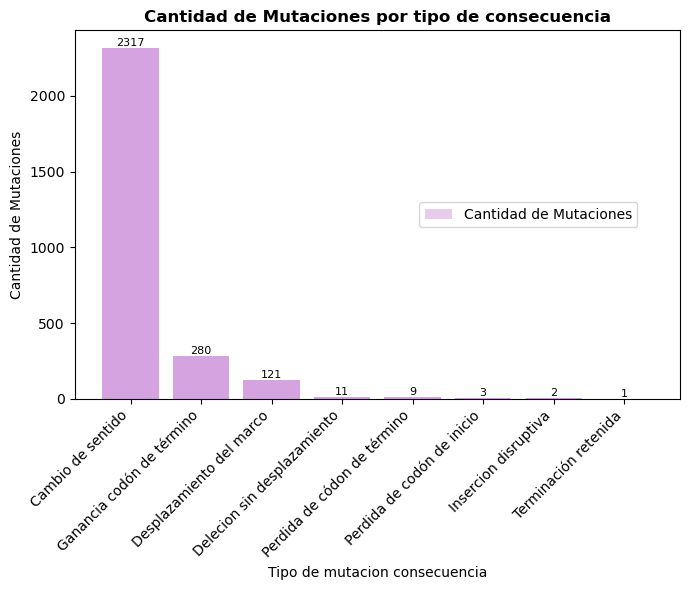

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
# Agrupar por consequence_type y contar el número de mutaciones únicas
mutation_counts = df_cancer.groupby('consequence_type')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts = mutation_counts.sort_values(by='num_mutaciones', ascending=False)

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='num_mutaciones', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)


# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(7, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['consequence_type'], mutation_counts["num_mutaciones"], color="#8800aa33")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['consequence_type'], mutation_counts['num_mutaciones'], color="#8800aa33",label='Cantidad de Mutaciones')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=8)


# Ajustar límites y etiquetas
ax.set_ylabel('Cantidad de Mutaciones', fontsize=10)
ax.set_xlabel('Tipo de mutacion consecuencia', fontsize=10)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['consequence_type'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['consequence_type'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.set_title('Cantidad de Mutaciones por tipo de consecuencia', weight='bold')
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/barras_mutation_number_CONSEQUENCE_{0}.svg".format(family_name), format='svg')

plt.show()



## Heatmap genes y tipo de cancer (normalizado)

In [25]:
ordered_cancer

NameError: name 'ordered_cancer' is not defined

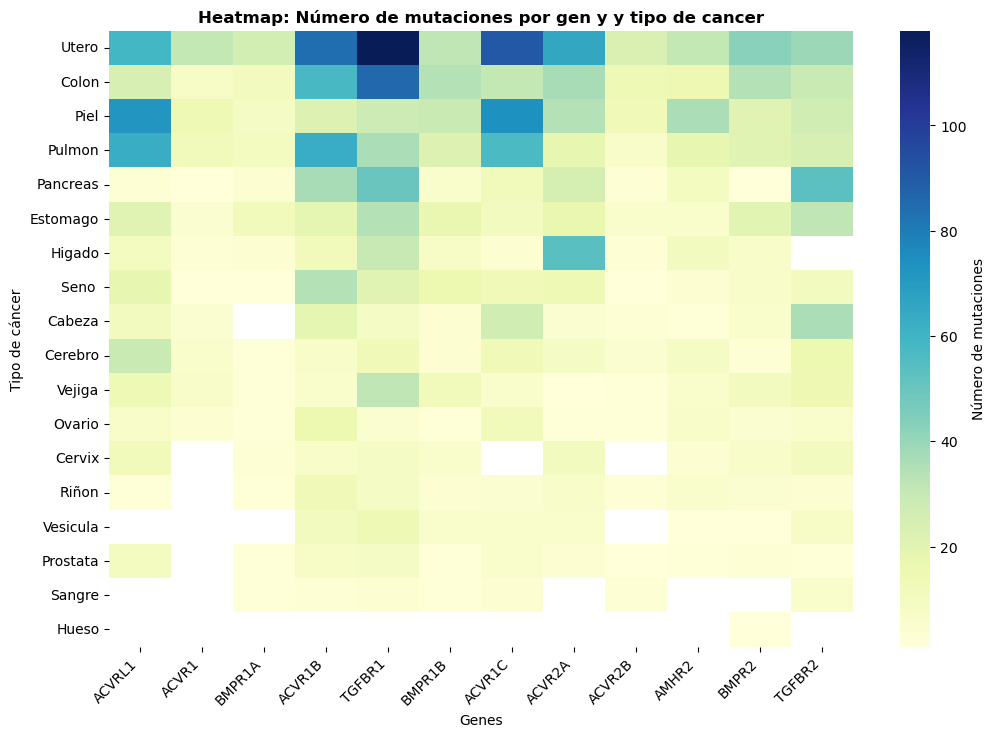

In [74]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
#ordered_genes = read_count_genes['Alias'].sort_values(ascending=True).unique()
#ordered_genes = ['ALK1', 'ALK2', 'ALK3', 'ALK4', 'ALK5', 'ALK6', 'ALK7','ACVR2A', 'ACVR2B','AMHR2', 'BMPR2', 'TGFBR2']
ordered_genes = ['ACVRL1', 'ACVR1', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'BMPR1B', 'ACVR1C','ACVR2A', 'ACVR2B','AMHR2', 'BMPR2', 'TGFBR2']
ordered_cancer = read_count.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index
#ordered_cancer = ['Ovario', 'Seno ', 'Prostata', 'Higado', 'Cabeza', 'Pulmon', 'Vejiga',
       #'Riñon', 'Cerebro', 'Estomago', 'Piel', 'Pancreas', 'Sangre', 'Colon',
       #'Cervix', 'Utero', 'Vesicula']
# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = read_count.pivot_table(
    index='tipo_cancer',
    columns='Gen_names',
    values='mutation_count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(columns=ordered_genes, index=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={'label': 'Número de mutaciones'})


# Ajustar las etiquetas  para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir título y etiquetas
plt.title("Heatmap: Número de mutaciones por gen y y tipo de cancer", weight='bold')
plt.ylabel("Tipo de cáncer")
plt.xlabel("Genes")

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/heatmap_mutation_crudo_{0}.png".format(family_name), format='png', dpi=600)

# Mostrar el gráfico
plt.show()

#eliminar numero

In [27]:
heatmap_data

Alias,ALK1,ALK2,ALK3,ALK4,ALK5,ALK6,ALK7,ACVR2A,ACVR2B,AMHR2,BMPR2,TGFBR2
tipo_cancer,,,,,,,,,,,,
Uterus,59.0,31.0,26.0,84.0,118.0,32.0,91.0,65.0,23.0,31.0,43.0,39.0
Colon,24.0,8.0,11.0,58.0,86.0,34.0,31.0,37.0,14.0,15.0,34.0,29.0
Skin,72.0,14.0,9.0,22.0,28.0,29.0,74.0,34.0,13.0,36.0,21.0,27.0
Lung,63.0,12.0,10.0,63.0,36.0,22.0,57.0,18.0,7.0,18.0,21.0,24.0
Pancreas,3.0,1.0,4.0,37.0,50.0,6.0,12.0,25.0,3.0,10.0,1.0,53.0
Stomach,21.0,5.0,12.0,19.0,34.0,17.0,11.0,17.0,6.0,6.0,20.0,32.0
Liver,10.0,3.0,4.0,12.0,30.0,8.0,4.0,54.0,3.0,11.0,7.0,NaN
Breast,18.0,1.0,1.0,34.0,21.0,16.0,13.0,14.0,1.0,4.0,7.0,11.0
Head,11.0,5.0,NaN,19.0,9.0,4.0,27.0,5.0,3.0,2.0,6.0,36.0


# Normalidad

## Z-core

In [28]:
read_count_pacientes

NameError: name 'read_count_pacientes' is not defined

In [29]:
ordered_cancer

Index(['Uterus', 'Colon', 'Skin', 'Lung', 'Pancreas', 'Stomach', 'Liver',
       'Breast', 'Head', 'Brain', 'Bladder', 'Ovary', 'Cervix', 'Kidney',
       'Gallbladder', 'Prostate', 'Blood', 'Bone'],
      dtype='object', name='tipo_cancer')

# Mutaciones tipo I y tipo II

In [30]:
data_agrupada = read_count.groupby(['tipo_cancer', 'tipo_receptor'])['mutation_count'].sum().reset_index()
data_agrupada.sort_values(by='mutation_count', ascending=False)

,tipo_cancer,tipo_receptor,mutation_count
33,Uterus,Tipo I,441
21,Lung,Tipo I,263
11,Colon,Tipo I,252
29,Skin,Tipo I,248
34,Uterus,Tipo II,201
30,Skin,Tipo II,131
12,Colon,Tipo II,129
31,Stomach,Tipo I,119
25,Pancreas,Tipo I,113
7,Breast,Tipo I,104


In [31]:
read_count.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index

Index(['Uterus', 'Colon', 'Skin', 'Lung', 'Pancreas', 'Stomach', 'Liver',
       'Breast', 'Head', 'Brain', 'Bladder', 'Ovary', 'Cervix', 'Kidney',
       'Gallbladder', 'Prostate', 'Blood', 'Bone'],
      dtype='object', name='tipo_cancer')

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agrupación explícita para confirmar la suma
data_agrupada = read_count.groupby(['tipo_cancer', 'tipo_receptor'])['mutation_count'].sum().reset_index()
data_agrupada = data_agrupada.sort_values(by='mutation_count', ascending=False)

order = ['Pulmon', 'Utero', 'Piel', 'Colon', 'Pancreas', 'Estomago', 'Higado',
       'Seno ', 'Cabeza', 'Vejiga', 'Cerebro', 'Riñon', 'Ovario', 'Cervix',
       'Prostata', 'Vesicula', 'Sangre', 'Hueso']

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

plt.figure(figsize=(12, 6))
sns.barplot(data=data_agrupada, x='tipo_cancer', y='mutation_count', hue='tipo_receptor', dodge=False, palette=my_palette, errorbar=None, order=order)  # Utilizando la paleta de colores categórica
plt.title('Numero de mutaciones por tipo de receptor')
plt.xticks(rotation=90)
plt.xlabel('Gen')
plt.ylabel('Número de mutaciones')
plt.legend(title='Frecuencia de alelo mutante')
plt.show()



# Distribucion de mutaciones

In [44]:
# Crea un diccionario para almacenar los DataFrames por gen
df_genes = {}

# Agrupa por 'Gen_names' y crea un DataFrame para cada grupo
for gen, grupo in df_mut.groupby('Gen_names'):
    df_genes[gen] = grupo.reset_index(drop=True)

# Imprimir DataFrames para cada gen
for gen, df_gen in df_genes.items():
    print(f"df_genes{[gen]}:")
    #print(df_gen, "\n")

df_genes['ACVR1']:
df_genes['ACVR1B']:
df_genes['ACVR1C']:
df_genes['ACVR2A']:
df_genes['ACVR2B']:
df_genes['ACVRL1']:
df_genes['AMHR2']:
df_genes['BMPR1A']:
df_genes['BMPR1B']:
df_genes['BMPR2']:
df_genes['TGFBR1']:
df_genes['TGFBR2']:


In [45]:
df_mut

,Gen_names,aa_mutation,tipo_cancer,total_read_count
0,ACVR1,A134T,Utero,164.0
1,ACVR1,A181P,Ovario,49.0
2,ACVR1,A233V,Piel,146.0
3,ACVR1,A317V,Utero,239.0
4,ACVR1,A471S,Colon,673.0
...,...,...,...,...
3124,TGFBR2,Y284D,Pancreas,108.0
3125,TGFBR2,Y424C,Estomago,78.0
3126,TGFBR2,Y449C,Estomago,78.0
3127,TGFBR2,YEE281,Colon,72.0


In [46]:
df_mut

,Gen_names,aa_mutation,tipo_cancer,total_read_count
0,ACVR1,A134T,Utero,164.0
1,ACVR1,A181P,Ovario,49.0
2,ACVR1,A233V,Piel,146.0
3,ACVR1,A317V,Utero,239.0
4,ACVR1,A471S,Colon,673.0
...,...,...,...,...
3124,TGFBR2,Y284D,Pancreas,108.0
3125,TGFBR2,Y424C,Estomago,78.0
3126,TGFBR2,Y449C,Estomago,78.0
3127,TGFBR2,YEE281,Colon,72.0


In [47]:
import pandas as pd

# Supongamos que este es tu DataFrame original


# Agrupar por gen y mutación, y contar los tipos de cáncer únicos
cancer_counts = df_mut.groupby(['Gen_names', 'aa_mutation'])['tipo_cancer'].unique().reset_index()

# Contar la cantidad de tipos de cáncer
cancer_counts['cantidad_canceres'] = cancer_counts['tipo_cancer'].apply(lambda x: len(x))

# Renombrar la columna de tipos de cáncer involucrados
cancer_counts.columns = ['Gen_names', 'aa_mutation', 'tipos_cancer_involucrados', 'cantidad_canceres']

# Mostrar el DataFrame resultante
cancer_counts.sort_values(by='cantidad_canceres')


,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres
0,ACVR1,A134T,[Utero],1
1821,BMPR1B,P456S,[Piel],1
1822,BMPR1B,P65S,[Seno ],1
1823,BMPR1B,P69S,[Vesicula],1
1824,BMPR1B,P87S,[Piel],1
...,...,...,...,...
2438,TGFBR1,R491Q,"[Estomago, Higado, Pancreas, Vesicula]",4
2576,TGFBR2,D471N,"[Cervix, Colon, Pancreas, Utero]",4
691,ACVR1C,R284*,"[Cerebro, Colon, Piel, Utero]",4
920,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6


In [48]:
cancer_counts['cantidad_canceres'].sum()

3129

In [49]:

# Filtrar las mutaciones que ocurren en más de un tipo de cáncer
repeated_mutations = cancer_counts[cancer_counts['cantidad_canceres'] > 1 ]
print(len(repeated_mutations))
print(repeated_mutations['Gen_names'].unique())
repeated_mutations

258
['ACVR1' 'ACVR1B' 'ACVR1C' 'ACVR2A' 'ACVR2B' 'ACVRL1' 'AMHR2' 'BMPR1A'
 'BMPR1B' 'BMPR2' 'TGFBR1' 'TGFBR2']


,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres
16,ACVR1,E38D?,"[Colon, Utero]",2
70,ACVR1,R375C,"[Colon, Ovario, Piel, Utero]",4
75,ACVR1,R490H,"[Cerebro, Utero]",2
83,ACVR1,V162M,"[Estomago, Utero]",2
175,ACVR1B,F184L,"[Riñon, Utero]",2
...,...,...,...,...
2768,TGFBR2,S320*,"[Cabeza, Pulmon]",2
2771,TGFBR2,S441F,"[Colon, Pancreas]",2
2773,TGFBR2,S466F,"[Colon, Pancreas]",2
2812,TGFBR2,W521*,"[Seno , Utero]",2


In [50]:
df_mut[df_mut['aa_mutation']=='R495*']

,Gen_names,aa_mutation,tipo_cancer,total_read_count
3025,TGFBR2,R495*,Estomago,89.0
3026,TGFBR2,R495*,Pancreas,84.0


In [51]:

# Filtrar las mutaciones que ocurren en más de un tipo de cáncer
repeated_mutations = cancer_counts[cancer_counts['cantidad_canceres'] > 5 ]
print(len(repeated_mutations))
print(repeated_mutations['Gen_names'].unique())
repeated_mutations

2
['ACVR2A']


,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres
920,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6
927,ACVR2A,K435,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6


In [52]:
# Crear la nueva columna 'cancer_invol'
cancer_counts['cancer_invol'] = cancer_counts['cantidad_canceres'].astype(str)

# Mostrar el DataFrame con la nueva columna
cancer_counts

,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol
0,ACVR1,A134T,[Utero],1,1
1,ACVR1,A181P,[Ovario],1,1
2,ACVR1,A233V,[Piel],1,1
3,ACVR1,A317V,[Utero],1,1
4,ACVR1,A471S,[Colon],1,1
...,...,...,...,...,...
2818,TGFBR2,Y284D,[Pancreas],1,1
2819,TGFBR2,Y424C,[Estomago],1,1
2820,TGFBR2,Y449C,[Estomago],1,1
2821,TGFBR2,YEE281,[Colon],1,1


In [53]:
# Filtrar las mutaciones que ocurren en más de un tipo de cáncer
repeated_mutations = cancer_counts[cancer_counts['cantidad_canceres'] > 4 ]
print(len(repeated_mutations))
print(repeated_mutations['Gen_names'].unique())
repeated_mutations

2
['ACVR2A']


,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol
920,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6
927,ACVR2A,K435,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6


In [54]:
# Convertir las listas de 'tipos_cancer_involucrados' a una cadena de texto sin corchetes y comillas
repeated_mutations['tipos_cancer_involucrados'] = repeated_mutations['tipos_cancer_involucrados'].apply(lambda x: ', '.join(x))
repeated_mutations

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_63980/1651583241.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  repeated_mutations['tipos_cancer_involucrados'] = repeated_mutations['tipos_cancer_involucrados'].apply(lambda x: ', '.join(x))


,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol
920,ACVR2A,K327,"Colon, Estomago, Higado, Pancreas, Utero, Vesi...",6,6
927,ACVR2A,K435,"Colon, Estomago, Higado, Pancreas, Utero, Vesi...",6,6


In [55]:
tabla = repeated_mutations.groupby(['Gen_names','tipos_cancer_involucrados']).size().reset_index(name='Count')
tabla.to_excel('mutaciones_agrupadas.xlsx', index=False)
tabla

,Gen_names,tipos_cancer_involucrados,Count
0,ACVR2A,"Colon, Estomago, Higado, Pancreas, Utero, Vesi...",2


In [56]:
df_mut_merge = df_mut[['aa_mutation', 'Gen_names','tipo_cancer']].merge(cancer_counts[['Gen_names', 'aa_mutation','cancer_invol']], on=['Gen_names', 'aa_mutation']) 
df_mut_merge_a=df_mut_merge.groupby(['Gen_names','cancer_invol'])['aa_mutation'].nunique().reset_index(name='Numero de mutaciones')
df_mut_merge_a

,Gen_names,cancer_invol,Numero de mutaciones
0,ACVR1,1,87
1,ACVR1,2,3
2,ACVR1,4,1
3,ACVR1B,1,368
4,ACVR1B,2,21
5,ACVR1B,3,3
6,ACVR1C,1,274
7,ACVR1C,2,41
8,ACVR1C,4,4
9,ACVR2A,1,233


In [57]:
df_mut_merge

,aa_mutation,Gen_names,tipo_cancer,cancer_invol
0,A134T,ACVR1,Utero,1
1,A181P,ACVR1,Ovario,1
2,A233V,ACVR1,Piel,1
3,A317V,ACVR1,Utero,1
4,A471S,ACVR1,Colon,1
...,...,...,...,...
3124,Y284D,TGFBR2,Pancreas,1
3125,Y424C,TGFBR2,Estomago,1
3126,Y449C,TGFBR2,Estomago,1
3127,YEE281,TGFBR2,Colon,1


In [58]:
# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
#mutation_frequencies_3 = cancer_counts.groupby(['tipo_cancer','Gen_names']).size().reset_index(name='mutation_count')
cancer_counts.sort_values(by='cantidad_canceres', ascending=False, inplace=True)
cancer_counts.reset_index(inplace = True, drop=True)
frecuencia_relativa = cancer_counts["cantidad_canceres"].cumsum()
total_defectos = cancer_counts["cantidad_canceres"].sum()
cancer_counts["relativa_acum_porcentual"] = frecuencia_relativa/total_defectos*100
cancer_counts

,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol,relativa_acum_porcentual
0,ACVR2A,K435,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.191755
1,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.383509
2,ACVR1,R375C,"[Colon, Ovario, Piel, Utero]",4,4,0.511345
3,ACVR1C,R391*,"[Cerebro, Colon, Piel, Utero]",4,4,0.639182
4,TGFBR2,D446N,"[Cervix, Colon, Pancreas, Utero]",4,4,0.767018
...,...,...,...,...,...,...
2818,ACVR2A,P399H,[Piel],1,1,99.872164
2819,ACVR2A,P507H,[Piel],1,1,99.904123
2820,ACVR2A,P62A,[Pancreas],1,1,99.936082
2821,ACVR2A,P62H,[Colon],1,1,99.968041


In [59]:
mutation_counts

,Dominio,mutation_count,relativa_acum_porcentual
0,Kinasa,1863,59.539789
1,Otro,1132,95.717482
2,GS,134,100.000000


In [60]:
invol_count=cancer_counts.groupby(['cancer_invol'])['aa_mutation'].count().reset_index()
invol_count

,cancer_invol,aa_mutation
0,1,2565
1,2,229
2,3,14
3,4,13
4,6,2


In [61]:
mutation_counts

,Dominio,mutation_count,relativa_acum_porcentual
0,Kinasa,1863,59.539789
1,Otro,1132,95.717482
2,GS,134,100.000000


In [62]:
mutation_counts

,Dominio,mutation_count,relativa_acum_porcentual
0,Kinasa,1863,59.539789
1,Otro,1132,95.717482
2,GS,134,100.000000


In [63]:
cancer_counts

,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol,relativa_acum_porcentual
0,ACVR2A,K435,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.191755
1,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.383509
2,ACVR1,R375C,"[Colon, Ovario, Piel, Utero]",4,4,0.511345
3,ACVR1C,R391*,"[Cerebro, Colon, Piel, Utero]",4,4,0.639182
4,TGFBR2,D446N,"[Cervix, Colon, Pancreas, Utero]",4,4,0.767018
...,...,...,...,...,...,...
2818,ACVR2A,P399H,[Piel],1,1,99.872164
2819,ACVR2A,P507H,[Piel],1,1,99.904123
2820,ACVR2A,P62A,[Pancreas],1,1,99.936082
2821,ACVR2A,P62H,[Colon],1,1,99.968041


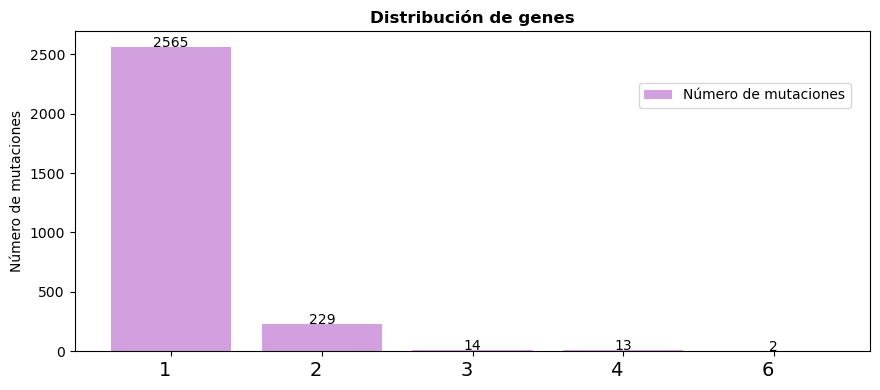

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df ya está definido y contiene las columnas necesarias

# Contar el número de mutaciones (aa_mutation) por tipo de cáncer involucrado
mutation_counts = cancer_counts.groupby(['cancer_invol'], as_index=False)['aa_mutation'].count()
mutation_counts.rename(columns={'aa_mutation': 'numero_mutaciones'}, inplace=True)

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='numero_mutaciones', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['numero_mutaciones'].cumsum() / mutation_counts['numero_mutaciones'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(9, 4))

# Gráfico de barras para el número de mutaciones por tipo de cáncer
bars = ax.bar(mutation_counts['cancer_invol'], mutation_counts['numero_mutaciones'], color="#8800aa5f", label='Número de mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
#ax2 = ax.twinx()
#ax2.plot(mutation_counts['cancer_invol'], mutation_counts['relativa_acum_porcentual'], color='C1', marker='o', ms=5, label='Frecuencia Relativa Acumulada')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height}', ha='center', va='baseline', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
#for i, value in enumerate(mutation_counts['relativa_acum_porcentual']):
   # ax2.text(i, value, f'{value:.1f}%', ha='left', va='top', color='red')

# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Frecuencia Relativa Acumulada (%)')
ax.set_title('Distribución de genes', weight='bold')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['cancer_invol'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['cancer_invol'], rotation=0, ha='right', fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center left', bbox_to_anchor=(0.7, 0.8))  # Leyenda del primer eje
ax2.legend(loc='center left', bbox_to_anchor=(0.1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/canceres_invol_{0}.png".format(family_name), format='png', dpi=600)

# Mostrar el gráfico
plt.show()


In [65]:
cancer_counts

,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol,relativa_acum_porcentual
0,ACVR2A,K435,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.191755
1,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.383509
2,ACVR1,R375C,"[Colon, Ovario, Piel, Utero]",4,4,0.511345
3,ACVR1C,R391*,"[Cerebro, Colon, Piel, Utero]",4,4,0.639182
4,TGFBR2,D446N,"[Cervix, Colon, Pancreas, Utero]",4,4,0.767018
...,...,...,...,...,...,...
2818,ACVR2A,P399H,[Piel],1,1,99.872164
2819,ACVR2A,P507H,[Piel],1,1,99.904123
2820,ACVR2A,P62A,[Pancreas],1,1,99.936082
2821,ACVR2A,P62H,[Colon],1,1,99.968041


In [66]:
alt.Chart(cancer_counts
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('cancer_invol:N', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    #color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['count(aa_mutation):Q']
).properties(
    title="Distrucion de mutaciones en cancer",
    width=1200,
    height=600
)

alt.Chart(...)

In [67]:
alt.Chart(cancer_counts
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('cantidad_canceres:N', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    #color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['count(aa_mutation):Q']
).properties(
    title="Distrucion de mutaciones en cancer",
    width=300,
    height=300
)

alt.Chart(...)

In [68]:
cancer_counts

,Gen_names,aa_mutation,tipos_cancer_involucrados,cantidad_canceres,cancer_invol,relativa_acum_porcentual
0,ACVR2A,K435,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.191755
1,ACVR2A,K327,"[Colon, Estomago, Higado, Pancreas, Utero, Ves...",6,6,0.383509
2,ACVR1,R375C,"[Colon, Ovario, Piel, Utero]",4,4,0.511345
3,ACVR1C,R391*,"[Cerebro, Colon, Piel, Utero]",4,4,0.639182
4,TGFBR2,D446N,"[Cervix, Colon, Pancreas, Utero]",4,4,0.767018
...,...,...,...,...,...,...
2818,ACVR2A,P399H,[Piel],1,1,99.872164
2819,ACVR2A,P507H,[Piel],1,1,99.904123
2820,ACVR2A,P62A,[Pancreas],1,1,99.936082
2821,ACVR2A,P62H,[Colon],1,1,99.968041


# Mutant allel frequency

In [69]:
ordered_cancer

Index(['Utero', 'Colon', 'Piel', 'Pulmon', 'Pancreas', 'Estomago', 'Higado',
       'Seno ', 'Cabeza', 'Cerebro', 'Vejiga', 'Ovario', 'Cervix', 'Riñon',
       'Vesicula', 'Prostata', 'Sangre', 'Hueso'],
      dtype='object', name='tipo_cancer')

In [70]:
df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False)

NameError: name 'df_unique' is not defined

In [71]:
ordered_cancer = df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
ordered_cancer

NameError: name 'df_unique' is not defined

In [ ]:
df_unique.sort_values(by='%mutant_allele_frequency',ascending=False)



In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_genes = df_unique.groupby('Gen_names')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
ordered_cancer = df_unique.groupby('tipo_cancer')['mutant_allele_frequency'].sum().sort_values(ascending=False).index
import seaborn as sns

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = df_unique.pivot_table(
    index='Gen_names',
    columns='tipo_cancer',
    values='mutant_allele_frequency',
    aggfunc='sum'
 # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Frecuencia de Mutaciones'})

# Añadir título y etiquetas
plt.title("Heatmap de Frecuencia de alelo mutante por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Gen")

# Mostrar el gráfico
plt.show()


## spìder rardar

In [ ]:
import plotly.express as px

custom_colors = [
    "#1f77b4",  # Azul
    "#ff7f0e",  # Naranja
    "#2ca02c",  # Verde
    "#d62728",  # Rojo
    "#9467bd",  # Púrpura
    "#8c564b",  # Marrón
    "#e377c2",  # Rosa
    "#7f7f7f",  # Gris
    "#bcbd22",  # Verde lima
    "#17becf",  # Azul cian
    "#1a55e2",  # Azul oscuro
    "#ff9896",  # Salmón
    "#98df8a",  # Verde claro
    "#c49c94",  # Beige
    "#f7b6d2",  # Rosa claro
    "#c7c7c7",  # Gris claro
    "#dbdb8d",  # Amarillo claro
    "#9edae5"   # Turquesa
]

# Primero, ordenar el DataFrame por número de mutaciones (mutation_count)
sort_mutation = mutation_frequencies_cancer_type.sort_values(by='mutation_count', ascending=False)

# Crear el gráfico polar
fig = px.line_polar(sort_mutation, r='mutation_count', theta='tipo_cancer', line_close=True, 
                    line_group='Gen_names', color='Gen_names', 
                    color_discrete_sequence=custom_colors)

# Rellenar el área bajo las líneas
fig.update_traces(fill='toself')

# Actualizar el layout para ordenar los ejes y definir el tamaño del gráfico
fig.update_layout(
    title='Grafico radar de numero de mutaciones por cancer y gen',  # Título del gráfico
    legend_title_text='Gene Names',  # Título de la leyenda
    width=1200,  # Ancho del gráfico (12 pulgadas)
    height=800,  # Altura del gráfico (8 pulgadas)
    title_font_size=20,  # Tamaño de la fuente del título
    legend=dict(font=dict(size=18)),  # Tamaño de la fuente de la leyenda
    polar=dict(
        angularaxis=dict(
            categoryorder='array',
            categoryarray=ordered_cancer  # Ordenar tipos de cáncer
        ),
        radialaxis=dict(
            visible=True
        )
    )
)

# Mostrar el gráfico
fig.show()


In [ ]:
a = mutation_frequencies_cancer_type.sort_values(by='mutation_count', ascending=False)
a['tipo_cancer'].unique()

In [ ]:
a

In [ ]:
# Libraries
import matplotlib.pyplot as plt
import pandas as pd
from math import pi
import numpy as np  # Para cálculo de filas/columnas

cancer_order = ['Utero', 'Piel', 'Colon', 'Pulmon', 'Estomago', 'Pancreas',
                  'Seno ', 'Cabeza', 'Higado', 'Cerebro', 'Vejiga', 'Cervix',
                  'Riñon', 'Ovario', 'Prostata', 'Gladd', 'Sangre']


# Ordenar el DataFrame según el número de mutaciones
mutation_frequencies_cancer_type = mutation_frequencies_cancer_type.sort_values(by='mutation_count', ascending=False)

# Ordenar el DataFrame según el orden deseado
mutation_frequencies_cancer_type['tipo_cancer'] = pd.Categorical(mutation_frequencies_cancer_type['tipo_cancer'], 
                                                                 categories=cancer_order, ordered=False)
mutation_frequencies_cancer_type = mutation_frequencies_cancer_type.sort_values(by='tipo_cancer')

def make_spider(row, title, ax, df):
    # Filtrar el DataFrame para el gen actual
    gene_data = mutation_frequencies_cancer_type[mutation_frequencies_cancer_type['Gen_names'] == title]

    # Filtrar solo los tipos de cáncer que tienen mutaciones asociadas
    gene_data = gene_data[gene_data['mutation_count'] > 0]

    # Si no hay datos para el gen, retornar
    if gene_data.empty:
        ax.set_visible(False)
        return

    # Número de variables (tipos de cáncer)
    categories = gene_data['tipo_cancer'].tolist()  # Obtenemos solo los tipos de cáncer que tienen datos
    N = len(categories)

    # Verificar si hay al menos un tipo de cáncer para graficar
    if N == 0:
        ax.set_visible(False)
        return

    # Ángulos de cada eje (dividir el gráfico en tantas partes como variables)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # Repetir el primer valor para cerrar el gráfico

    # Ajustar el ángulo inicial para que la primera variable esté en la parte superior
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)

    # Dibujar un eje por variable y añadir las etiquetas
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, color='black', size=10, rotation=0, ha='center', va='center')  # Ajustar el 'pad'

    # Dibujar las etiquetas de los ejes radiales
    ax.set_rlabel_position(0)

    # Ajustar los ticks del eje radial
    yticks_values = np.linspace(0, gene_data['mutation_count'].max() + 5, num=5)  # Crear ticks
    ax.set_yticks(yticks_values)  # Establecer los ticks
    ax.set_yticklabels([f"{int(val)}" for val in yticks_values], color="black", size=8)  # Etiquetas de los ticks

    # Establecer los límites del eje radial
    ax.set_ylim(0, gene_data['mutation_count'].max() + 5)

    # Valores (mutation_count) para el gráfico
    values = gene_data['mutation_count'].tolist()
    values += values[:1]  # Repetir el primer valor para cerrar el gráfico

    # Determinar el color de la línea
    color = 'blue'  # Obtener el color basado en el primer tipo de cáncer

    # Dibujar la línea y rellenar el área
    ax.plot(angles, values, color=color, linewidth=2, linestyle='solid')
    ax.fill(angles, values, color=color, alpha=0.2)

    # Añadir un título
    ax.set_title(title, size=11, color=color, y=1.1)

# ------- PART 2: Calcular el tamaño de la cuadrícula según la cantidad de genes

genes = mutation_frequencies_cancer_type['Gen_names'].unique()  # Lista de genes
num_plots = len(genes)

# Calcular filas y columnas necesarias
num_cols = 4  # Puedes ajustar este valor si deseas más o menos columnas
num_rows = int(np.ceil(num_plots / num_cols))

# Ajustar el tamaño de la figura (aumentar proporción a medida que hay más gráficos)
figsize_ratio = 5  # Ajusta este valor para aumentar el tamaño
fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * figsize_ratio, num_rows * figsize_ratio), subplot_kw=dict(polar=True))

# Iterar sobre cada gen y aplicar la función make_spider para cada uno
for i, gene in enumerate(genes):
    # Seleccionar el subplot correcto
    ax = axes[i // num_cols, i % num_cols] if num_plots > 1 else axes  # Soporte para un solo gráfico

    # Generar el gráfico para el gen
    make_spider(row=i, title=gene, ax=ax, df=mutation_frequencies_cancer_type)

# Ajustar el espaciado entre gráficos
plt.subplots_adjust(hspace=0.3, wspace=0.5)  # Ajustar espacio entre gráficos

# Mostrar el gráfico
plt.show()


In [ ]:
mutation_frequencies_cancer_type.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index

In [ ]:
ordered_cancer 

In [ ]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Primero, ordenar el DataFrame por número de mutaciones (mutation_count)
sort_mutation = mutation_frequencies_cancer_type.sort_values(by='mutation_count', ascending=False)

# Obtener el orden para los tipos de cáncer
ordered_cancer = sort_mutation['tipo_cancer'].unique()

# Obtener todos los genes únicos
genes = sort_mutation['Gen_names'].unique()

# Calcular cuántas filas se necesitarán para los gráficos, teniendo en cuenta que serán 3 columnas
n_rows = (len(genes) + 2) // 3  # +2 para redondear hacia arriba

# Crear una figura con subplots (3 columnas y las filas necesarias)
fig = make_subplots(rows=n_rows, cols=3, subplot_titles=genes, 
                    specs=[[{'type': 'polar'}]*3]*n_rows)

# Iterar sobre cada gen y añadir el gráfico a la subfigura correspondiente
for i, gene in enumerate(genes):
    # Filtrar el DataFrame para el gen actual
    gene_data = mutation_frequencies_cancer_type[mutation_frequencies_cancer_type['Gen_names'] == gene]
    
    # Crear el gráfico polar para el gen con el mismo orden de tipos de cáncer
    polar_trace = go.Scatterpolar(
        r=gene_data['mutation_count'],   # Radios
        theta=gene_data['tipo_cancer'],  # Ángulos (tipos de cáncer)
        fill='none',                   # Para rellenar el área dentro de la gráfica
        name=gene                        # Nombre del gen
    )
    
    # Determinar la fila y columna en la que debe ir el gráfico
    row = i // 3 + 1  # Cambiado a 3 columnas
    col = i % 3 + 1
    
    # Añadir el gráfico a la subfigura correspondiente
    fig.add_trace(polar_trace, row=row, col=col)

# Ajustar el layout de los ejes angulares para mantener el orden de los tipos de cáncer
fig.update_polars(
    angularaxis=dict(
        categoryorder='array',
        categoryarray=ordered_cancer  # Mantener el mismo orden de tipos de cáncer
    )
)

# Ajustar el layout general
fig.update_layout(
    height=500*n_rows,  # Ajustar la altura según el número de filas
    width=1000,         # Ajustar el ancho total
    title_text="Mutation Frequency by Cancer Type for Each Gene",  # Título general
    showlegend=False    # Ocultar leyenda para evitar redundancia
)

# Mostrar el gráfico
fig.show()



In [ ]:

chart2=alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    tooltip=['Gen_names', 'count()']
).properties(
    title="Numero de mutaciones por gen"
)
chart3 =  alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['tipo_cancer','aa_mutation','Gen_names']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    tooltip=['tipo_cancer', 'count()']
).properties(
    title="Numero de mutaciones por gen"
)
chart2|chart3

In [ ]:
import pandas as pd
import altair as alt


# Calcular las frecuencias de las mutaciones
frecuencias = df_cancer['aa_mutation'].value_counts().reset_index()
frecuencias.columns = ['aa_mutation', 'frecuencia']

# Filtrar las mutaciones más frecuentes (por ejemplo, las 10 más frecuentes)
top_n = 20  # Cambia este valor según lo que necesites
mutaciones_frecuentes = frecuencias.nlargest(top_n, 'frecuencia')

# Filtrar el DataFrame original para incluir solo las mutaciones más frecuentes
df_filtrado = df_cancer[df_cancer['aa_mutation'].isin(mutaciones_frecuentes['aa_mutation'])]

# Crear el histograma
histograma = alt.Chart(df_filtrado).mark_bar().encode(
    x=alt.X('aa_mutation:N', title='Mutación AA', sort='-y'),
    y=alt.Y('count():Q', title='Frecuencia'),
    color=alt.Color('tipo_cancer:N', scale=alt.Scale(scheme='category20')),
    tooltip=['tipo_cancer:N', 'aa_mutation:N', 'count():Q']
).properties(
    title='Histograma de Mutaciones por Tipo de Cáncer (Mutaciones Más Frecuentes)'
)

# Mostrar el gráfico
histograma


In [ ]:
df_filtrado['aa_mutation'].unique()

In [ ]:
import pandas as pd
import altair as alt


# Contar la frecuencia de cada mutación
mutation_counts = df_cancer.groupby('aa_mutation').size().reset_index(name='count')

# Filtrar las mutaciones con frecuencia mayor a 5
filtered_mutations = mutation_counts.query('count > 0')

# Filtrar el DataFrame original
df_filtered = df_cancer[df_cancer['aa_mutation'].isin(filtered_mutations['aa_mutation'])]

# Crear el histograma
histogram = alt.Chart(df_filtered).mark_bar().encode(
    x=alt.X('aa_mutation:N', title='Mutación AA', sort='-y'),
    y=alt.Y('count():Q', title='Frecuencia'),
    color=alt.Color('tipo_cancer', scale=alt.Scale(scheme='category20')),
    tooltip=['tipo_cancer:N', 'aa_mutation:N', 'count():Q']
).transform_filter(
    alt.FieldOneOfPredicate(field='aa_mutation', oneOf=filtered_mutations['aa_mutation'].tolist())
).properties(
    title='Histograma de Mutaciones por Tipo de Cáncer (Frecuencia > 5)'
)

# Mostrar el histograma
histogram

In [ ]:
import pandas as pd

# Calcular las frecuencias de las mutaciones por gen
frecuencias_por_gen = df_cancer.groupby('Gen_names')['aa_mutation'].value_counts().reset_index(name='frecuencia')

# Filtrar las 100 mutaciones más frecuentes por gen
top_n = 20  # Cambia este valor según lo que necesites
mutaciones_frecuentes_por_gen = frecuencias_por_gen.groupby('Gen_names').apply(lambda x: x.nlargest(top_n, 'frecuencia')).reset_index(drop=True)

# Crear una lista de mutaciones para cada gen
mutaciones_por_gen = mutaciones_frecuentes_por_gen.groupby('Gen_names')['aa_mutation'].apply(list).reset_index()

# Renombrar las columnas para mayor claridad
mutaciones_por_gen.columns = ['Gen', 'Lista de Mutaciones']

# Mostrar la lista de mutaciones para cada gen
for index, row in mutaciones_por_gen.iterrows():
    print(f"Gen: {row['Gen']}")
    print("Lista de Mutaciones:")
    print(row['Lista de Mutaciones'])
    print("\n")


# Step 2: Numero de mutaciones por tipo de cancer y gen

In [ ]:
# Grafica el numero de mutaciones por tipo de cancer, y representa consequence type por color
# crea una lista despegable para cada tipo de cancer
import altair as alt
import pandas as pd

# Lista con los tipos de cancer, que estaran en la lista desplegable

lista = df_cancer['tipo_cancer'].unique()
print(lista)

# DataFrame llamado df_cancer
alt.data_transformers.enable('default', max_rows=None) #configura las transformaciones de datos de Altair para manejar todos los datos, incluso si hay un gran número de filas en el DataFrame.
#al  utilizar max_rows=None, Altair no establecerá un límite máximo en el número de filas a utilizar
# Crear un gráfico 'base' con todos los datos
base=alt.Chart(df_cancer
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q'),
    x=alt.X('Gen_names:N', sort='-y'),
    color=alt.Color('consequence_type', scale=alt.Scale(scheme='category20'))
    #color para mas de 20 categorias
).properties(
    title='Gráfico de Tipos de Cáncer' #Titulo del grafico
)

# Crear una selección desplegable (dropdown) para los tipos de cáncer
tipo_cancer_dropdown = alt.binding_select(options=df_cancer['tipo_cancer'].unique().tolist(), name='Seleccionar Tipo de Cáncer:')
selection = alt.selection_point(fields=['tipo_cancer'], bind=tipo_cancer_dropdown, name='Seleccion')


# Aplicar la selección para filtrar los datos
filtered_chart = base.add_params(selection).transform_filter(selection)

# Visualizar el gráfico 
filtered_chart


**Mutaciones de genes TKL por tipo de cancer**

In [ ]:
g1=alt.Chart(df_cancer
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Tipo de cancer', axis=alt.Axis(
              labelAngle=40, labelFontSize=12))
).properties(
    title="Numero de mutaciones por tipo de cancer"
)


g3=alt.Chart(df_cancer
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes', axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
).properties(
    title="Numero de mutaciones por gen"
)

# Agrupar por consequence_type y contar el número de mutaciones únicas
mutation_counts = df_cancer.groupby('consequence_type')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts = mutation_counts.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts.iterrows():
    print(f"Número de mutaciones {row['consequence_type']}: {row['num_mutaciones']}")

print('-----------------------------------------------')

# Agrupar por TK_Name y contar el número de mutaciones únicas
mutation_counts_gen = df_cancer.groupby('Gen_names')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts_gen = mutation_counts_gen.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts_gen.iterrows():
    print(f"Número de mutaciones {row['Gen_names']}: {row['num_mutaciones']}")

print('-----------------------------------------------')

# Agrupar por TK_Name y contar el número de mutaciones únicas
mutation_counts_cancer = df_cancer.groupby('tipo_cancer')['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts_cancer = mutation_counts_cancer.sort_values(by='num_mutaciones', ascending=False)

# Imprimir el número de mutaciones para cada consequence_type
for index, row in mutation_counts_cancer.iterrows():
    print(f"Número de mutaciones {row['tipo_cancer']}: {row['num_mutaciones']}")
(g1|g3)



**Crea un DataFrame con la data para cada tipo de cancer**

In [ ]:
df_consequence = df_cancer[['aa_mutation','consequence_type']]

In [ ]:
df_consequence = df_cancer[['aa_mutation','consequence_type']]

# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_consequence = df_consequence.drop_duplicates(subset=['aa_mutation','consequence_type'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_consequence = df_consequence.groupby(['consequence_type']).size().reset_index(name='mutation_count')

# Paso 3: Contar el número total de pacientes
total_mutation = df_cancer['aa_mutation'].nunique()

# Paso 4: Calcular la frecuencia de mutación como la proporción de mutaciones por gen al número total de pacientes
mutation_frequencies_consequence['mutation_frequency'] = (mutation_frequencies_consequence['mutation_count'] / total_mutation)*100

# Paso 5: Mostrar los resultados
mutation_frequencies_consequence.sort_values(ascending=False, by='mutation_count')

In [ ]:
base = alt.Chart(mutation_frequencies_consequence).mark_arc().encode(
    theta=alt.Theta('mutation_count:Q', sort='descending'),  # Ordenar de mayor a menor,
    color="consequence_type"
).properties(
    title='Tipo de mutacion mas frecuente en cancer'
)


base

In [ ]:
import altair as alt



alt.Chart(df_cancer).mark_bar().encode(
    x=alt.X('tipo_cancer',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    y=alt.Y('count(aa_mutation):Q', scale=alt.Scale(domain=[0, 150])).title('Numero de mutaciones').axis(format='.0f'),
    facet=alt.Facet('Gen_names').columns(4),
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
    tooltip=['count(aa_mutation):Q', 'Gen_names','tipo_cancer']
).properties(
    title='Mutaciones por gen en cada tipo de cancer',
    width=250,
    height=80
)

In [ ]:
df_cancer['aa_mutation'].nunique()

In [ ]:
# crea una lista con los 18 tipos de cancer a tratar
lista_cancer = df_cancer['tipo_cancer'].unique()
#Crea un dataframe para cada tipo de grafico, para poder graficarlos de forma independiente
dict_cancer = {}

# Iterar sobre cada tipo de cáncer en lista_cancer
for tipo in lista_cancer:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes al tipo de cáncer actual
    df_tipo_cancer = df_cancer[df_cancer['tipo_cancer'] == tipo]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente al tipo de cáncer
    dict_cancer[tipo] = df_tipo_cancer

# Ahora se puede acceder a cada DataFrame utilizando la clave correspondiente al tipo de cáncer en el diccionario

cancer_cabeza = dict_cancer['Cabeza']


In [ ]:
lista_cancer

In [ ]:
dict_cancer['Seno '].head()

# Grafico para cada tipo de cancer
Se utiliza el parametro scale=alt.Scale(domain=[]), para especificar el rango de valores que se mostrarán en el eje y. Para asegurar una comparación visual adecuada entre los diferentes conjuntos de datos

In [ ]:
import altair as alt
import pandas as pd


# Suponiendo que df_cancer ya está definido y contiene los datos
# Generar la lista de tipos de cáncer y el diccionario de DataFrames
lista_cancer = df_cancer['tipo_cancer'].unique()
dict_cancer = {tipo: df_cancer[df_cancer['tipo_cancer'] == tipo] for tipo in lista_cancer}

alt.data_transformers.enable('default', max_rows=None)

# Definir grupos de tipos de cáncer por dominios de ejes y
grupos_cancer = {
    'Grupo 1': ['Utero', 'Colon','Piel', 'Pulmon'],
    'Grupo 2': ['Estomago', 'Pancreas', 'Higado', 'Seno ', 'Cabeza', 'Vejiga', 'Cerebro'],
    'Grupo 3': ['Ovario', 'Cervix', 'Riñon', 'Vesicula', 'Prostata'],
    'Grupo 4': ['Sangre']
    # Agrega más grupos según sea necesario
}

# Definir los dominios para cada grupo
dominios = {
    'Grupo 1': [0, 150],
    'Grupo 2': [0, 80],
    'Grupo 3': [0, 20],
    'Grupo 4': [0, 10]
    # Define más dominios según sea necesario
}

# Función para crear un gráfico para un tipo de cáncer específico
def create_cancer_chart(cancer_type, domain):
    chart = alt.Chart(dict_cancer[cancer_type]).mark_bar().encode(
        y=alt.Y('count(aa_mutation):Q', title='Numero de mutaciones', scale=alt.Scale(domain=domain)),
        x=alt.X('Gen_names', sort='-y', title='Genes STKR'),
        color=alt.Color('consequence_type', scale=alt.Scale(scheme='category20'))
    ).properties(
        title=cancer_type,
        width=200,
        height=200
    )
    return chart

# Crear los gráficos agrupados por dominios
graficos_agrupados = {grupo: [] for grupo in grupos_cancer.keys()}
for grupo, tipos in grupos_cancer.items():
    for tipo in tipos:
        chart = create_cancer_chart(tipo, dominios[grupo])
        graficos_agrupados[grupo].append(chart)

# Función para mostrar gráficos de un grupo específico
def mostrar_graficos_grupo(grupo):
    charts = graficos_agrupados[grupo]
    grid = alt.hconcat(*charts)
    return grid

In [ ]:
# Mostrar gráficos del Grupo 1
mostrar_graficos_grupo('Grupo 1')




In [ ]:
mostrar_graficos_grupo('Grupo 2')

In [ ]:
mostrar_graficos_grupo('Grupo 3')

In [ ]:
mostrar_graficos_grupo('Grupo 4')

In [ ]:
df_cancer.shape

# Total de mutaciones por cancer

In [ ]:
for tipo_cancer, data in sorted(dict_cancer.items(), key=lambda x: len(x[1]['aa_mutation'].unique()), reverse=True):
    print(f"Número de mutaciones en cáncer de {tipo_cancer}: {len(data['aa_mutation'].unique())}")


In [ ]:
import pandas as pd

# Crear una lista de diccionarios con los datos
data_list = []
for tipo_cancer, data in sorted(dict_cancer.items(), key=lambda x: len(x[1]['aa_mutation'].unique()), reverse=True):
    data_list.append({'Gen_names': tipo_cancer, 'Número de mutaciones': len(data['aa_mutation'].unique())})

# Crear un DataFrame de Pandas
df2 = pd.DataFrame(data_list)

df2


In [ ]:
chart2=alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['tipo_cancer','aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
).properties(
    title="Numero de mutaciones por gen"
)
chart2

In [ ]:
alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(icgc_mutation_id)',
    groupby=['Gen_names','icgc_mutation_id', 'clasificacion']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color = 'clasificacion'
).properties(
    title="Numero de mutaciones por gen"
)

In [ ]:
acr1=df_cancer.loc[df_cancer['Gen_names']=='ACVR1']
len(acr1['aa_mutation'])

In [ ]:
#Crea un dataframe para cada tipo de grafico, para poder graficarlos de forma independiente
lista_genes = df_cancer['Gen_names'].unique() 

dict_gen = {}

# Iterar sobre cada tipo de cáncer en lista_cancer
for gen in lista_genes:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes al tipo de cáncer actual
    df_gen = df_cancer[df_cancer['Gen_names'] == gen]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente al tipo de cáncer
    dict_gen[gen] = df_gen

# Ahora se puede acceder a cada DataFrame utilizando la clave correspondiente al tipo de cáncer en el diccionario

dict_gen['BMPR1B']


In [ ]:
len(dict_gen['ACVR1']['aa_mutation'].unique())

# Mutaciones por gen

In [ ]:
import pandas as pd

# Crear una lista de diccionarios con los datos
data_lista = []
for TK_Name, data in sorted(dict_gen.items(), key=lambda x: len(x[1]['aa_mutation'].unique()), reverse=True):
    data_lista.append({'Gen': TK_Name, 'Número de mutaciones': len(data['aa_mutation'].unique())})

# Crear un DataFrame de Pandas
df_ = pd.DataFrame(data_lista)

df_


In [ ]:
len(dict_gen['ACVR1']['aa_mutation'].unique())

In [ ]:
len(dict_gen['TGFBR1']['aa_mutation'].unique())

# Mutaciones en ACVR1

In [ ]:
chart2=alt.Chart(dict_gen['ACVR1']
).mark_bar().encode(
    y=alt.Y('count(aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes STKR', axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color = 'clasificacion'
).properties(
    title="Expresion de ACVR1 en cáncer"
)
chart3=alt.Chart(dict_gen['ACVR1']).mark_arc().encode(
    theta='count(aa_mutation):Q',
    color="consequence_type"
).properties(
    title='Tipo de mutacion mas frecuente en ACVR1'
)
chart2|chart3

 # Frecuencia de mutaciones por tipo de cancer

In [ ]:
df_cancer.shape

In [ ]:
df_cancer['clasificacion'].unique()

In [ ]:
df_cancer.columns

In [ ]:
alta_frecuencia = df_cancer[df_cancer['clasificacion']=='Alta frecuencia']
media_frecuencia = df_cancer[df_cancer['clasificacion']=='Media frecuencia']
muy_alta_frecuencia = df_cancer[df_cancer['clasificacion']=='Muy alta frecuencia']
baja_frecuencia = df_cancer[df_cancer['clasificacion']=='Baja frecuencia']


In [ ]:
len(df_cancer['aa_mutation'].unique())

In [ ]:
len(media_frecuencia['aa_mutation'].unique())

In [ ]:
import pandas as pd

# Supongamos que ya tienes los DataFrames: alta_frecuencia, media_frecuencia, muy_alta_frecuencia, baja_frecuencia

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
alta_frecuencia_mutaciones = alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Contar el número de mutaciones por gen y tipo de cáncer para media_frecuencia
media_frecuencia_mutaciones = media_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Contar el número de mutaciones por gen y tipo de cáncer para muy_alta_frecuencia
muy_alta_frecuencia_mutaciones = muy_alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Contar el número de mutaciones por gen y tipo de cáncer para baja_frecuencia
baja_frecuencia_mutaciones = baja_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].size().reset_index(name='num_mutaciones')

# Revisar las mutaciones para alta_frecuencia
alta_frecuencia_detalle = alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Revisar las mutaciones para media_frecuencia
media_frecuencia_detalle = media_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Revisar las mutaciones para muy_alta_frecuencia
muy_alta_frecuencia_detalle = muy_alta_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Revisar las mutaciones para baja_frecuencia
baja_frecuencia_detalle = baja_frecuencia.groupby(['Gen_names', 'tipo_cancer', 'project_code'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Mostrar los resultados
print("Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(alta_frecuencia_mutaciones)

print("\nMedia Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(media_frecuencia_mutaciones)

print("\nMuy Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(muy_alta_frecuencia_mutaciones)

print("\nBaja Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
print(baja_frecuencia_mutaciones)

print("\nAlta Frecuencia - Detalle de mutaciones:")
print(alta_frecuencia_detalle)

print("\nMedia Frecuencia - Detalle de mutaciones:")
print(media_frecuencia_detalle)

print("\nMuy Alta Frecuencia - Detalle de mutaciones:")
print(muy_alta_frecuencia_detalle)

print("\nBaja Frecuencia - Detalle de mutaciones:")
print(baja_frecuencia_detalle)


In [ ]:
print("\nBaja Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
baja_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False)


In [ ]:
print("\nMuy Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
muy_alta_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False)

In [ ]:
print("\nMedia Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
media_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False)

In [ ]:

print("Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer:")
alta_frecuencia_mutaciones.sort_values(by='num_mutaciones', ascending=False).reset_index(drop=True)


In [ ]:
print("\nBaja Frecuencia - Detalle de mutaciones:")
baja_frecuencia_detalle


In [ ]:

print("\nMuy Alta Frecuencia - Detalle de mutaciones:")
muy_alta_frecuencia_detalle

In [ ]:
print("\nMedia Frecuencia - Detalle de mutaciones:")
media_frecuencia_detalle

In [ ]:

print("\nAlta Frecuencia - Detalle de mutaciones:")
alta_frecuencia_detalle

In [ ]:
print("\nBaja Frecuencia - Detalle de mutaciones:")
baja_frecuencia_detalle

In [ ]:
print(f"Numero de mutaciones: {df_cancer['aa_mutation'].nunique()}")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

# Crear las visualizaciones
def plot_mutation_counts(df, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='tipo_cancer', y='num_mutaciones', hue='Gen_names', dodge=True, palette=my_palette)  # Utilizando la paleta de colores categórica
    plt.title(title)
    plt.xticks(rotation=90)
    plt.xlabel('tipo_cancer')
    plt.ylabel('Número de mutaciones')
    plt.legend(title='Gen')
    plt.show()

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
alta_frecuencia_mutaciones = alta_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(alta_frecuencia_mutaciones, 'Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer')

# Contar el número de mutaciones por gen y tipo de cáncer para media_frecuencia
media_frecuencia_mutaciones = media_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(media_frecuencia_mutaciones, 'Media Frecuencia - Número de mutaciones por gen y tipo de cáncer')

# Contar el número de mutaciones por gen y tipo de cáncer para muy_alta_frecuencia
muy_alta_frecuencia_mutaciones = muy_alta_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(muy_alta_frecuencia_mutaciones, 'Muy Alta Frecuencia - Número de mutaciones por gen y tipo de cáncer')

# Contar el número de mutaciones por gen y tipo de cáncer para baja_frecuencia
baja_frecuencia_mutaciones = baja_frecuencia.groupby(['Gen_names', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(baja_frecuencia_mutaciones, 'Baja Frecuencia - Número de mutaciones por gen y tipo de cáncer')


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

# Crear las visualizaciones
def plot_mutation_counts(df, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='tipo_cancer', y='num_mutaciones', hue='clasificacion', dodge=True, palette=my_palette)  # Utilizando la paleta de colores categórica
    plt.title(title)
    plt.xticks(rotation=90)
    plt.xlabel('tipo_cancer')
    plt.ylabel('Número de mutaciones')
    plt.legend(title='Frecuencia de alelo mutante')
    plt.show()

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
frecuencia_alelo_mutante = df_cancer.groupby(['clasificacion', 'tipo_cancer'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(frecuencia_alelo_mutante, 'Número de mutaciones por tipo de cáncer')



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir una paleta de colores categórica
my_palette = sns.color_palette("Set1") + sns.color_palette("Set2")

# Crear las visualizaciones
def plot_mutation_counts(df, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df, x='Gen_names', y='num_mutaciones', hue='clasificacion', dodge=True, palette=my_palette)  # Utilizando la paleta de colores categórica
    plt.title(title)
    plt.xticks(rotation=90)
    plt.xlabel('Gen')
    plt.ylabel('Número de mutaciones')
    plt.legend(title='Frecuencia de alelo mutante')
    plt.show()

# Contar el número de mutaciones por gen y tipo de cáncer para alta_frecuencia
frecuencia_alelo_mutante = df_cancer.groupby(['clasificacion', 'Gen_names'])['aa_mutation'].size().reset_index(name='num_mutaciones')
plot_mutation_counts(frecuencia_alelo_mutante, 'Número de mutaciones por Gen')



In [ ]:
df_cancer

In [ ]:
#interpro_code = 'IPR000333'
family_name = 'STKR'
# Guardar los detalles de mutaciones en formato CSV
#alta_frecuencia_detalle.to_csv('../data/mutaciones/alta_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
#media_frecuencia_detalle.to_csv('../data/mutaciones/media_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
#muy_alta_frecuencia_detalle.to_csv('../data/mutaciones/muy_alta_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
#baja_frecuencia_detalle.to_csv('../data/mutaciones/baja_frecuencia_detalle_{0}.csv'.format(family_name), index=False)
df_cancer.to_csv('../data/mutaciones/mutaciones_aa_{0}'.format(family_name), index=False)

In [ ]:
df_cancer.shape